# Data Analysis

## Data Inspection

In [22]:
#Install library dependecies
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from plotnine import *

In [9]:
#Import the dataset
df = pd.read_csv(
    "Datasets/pima-indians-diabetes-resampled.csv"
)

In [10]:
#gives a quick overview of the dataset
df.head()

,Preg,Glucose,BP,Skin,Insulin,BMI,Pedigree,Age,HasDiabetes
0,2,157,74,35,440,39.4,0.134,30,0
1,7,159,64,0,0,27.4,0.294,40,0
2,7,83,78,26,71,29.3,0.767,36,0
3,0,124,56,13,105,21.8,0.452,21,0
4,5,99,54,28,83,34.0,0.499,30,0


In [ ]:
# Returnrs missing values in the dataset, duplicate rows, and summary statistics
print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nSummary Statistics:")
display(df.describe())


Missing Values:
Preg           0
Glucose        0
BP             0
Skin           0
Insulin        0
BMI            0
Pedigree       0
Age            0
HasDiabetes    0
dtype: int64

Duplicate Rows:
0

Summary Statistics:


,Preg,Glucose,BP,Skin,Insulin,BMI,Pedigree,Age,HasDiabetes
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [ ]:
# Returns the count of medically invalid zero values in specific columns
medical_columns = [
    "Glucose",
    "BP",
    "Skin",
    "Insulin",
    "BMI"
]

print("Medically invalid zero values:\n")

for col in medical_columns:
    count = (df[col] == 0).sum()
    percentage = (count / len(df)) * 100

    print(f"{col}: {count} ({percentage:.2f}%)")

Medically invalid zero values:

Glucose: 5 (0.65%)
BP: 35 (4.56%)
Skin: 227 (29.56%)
Insulin: 374 (48.70%)
BMI: 11 (1.43%)


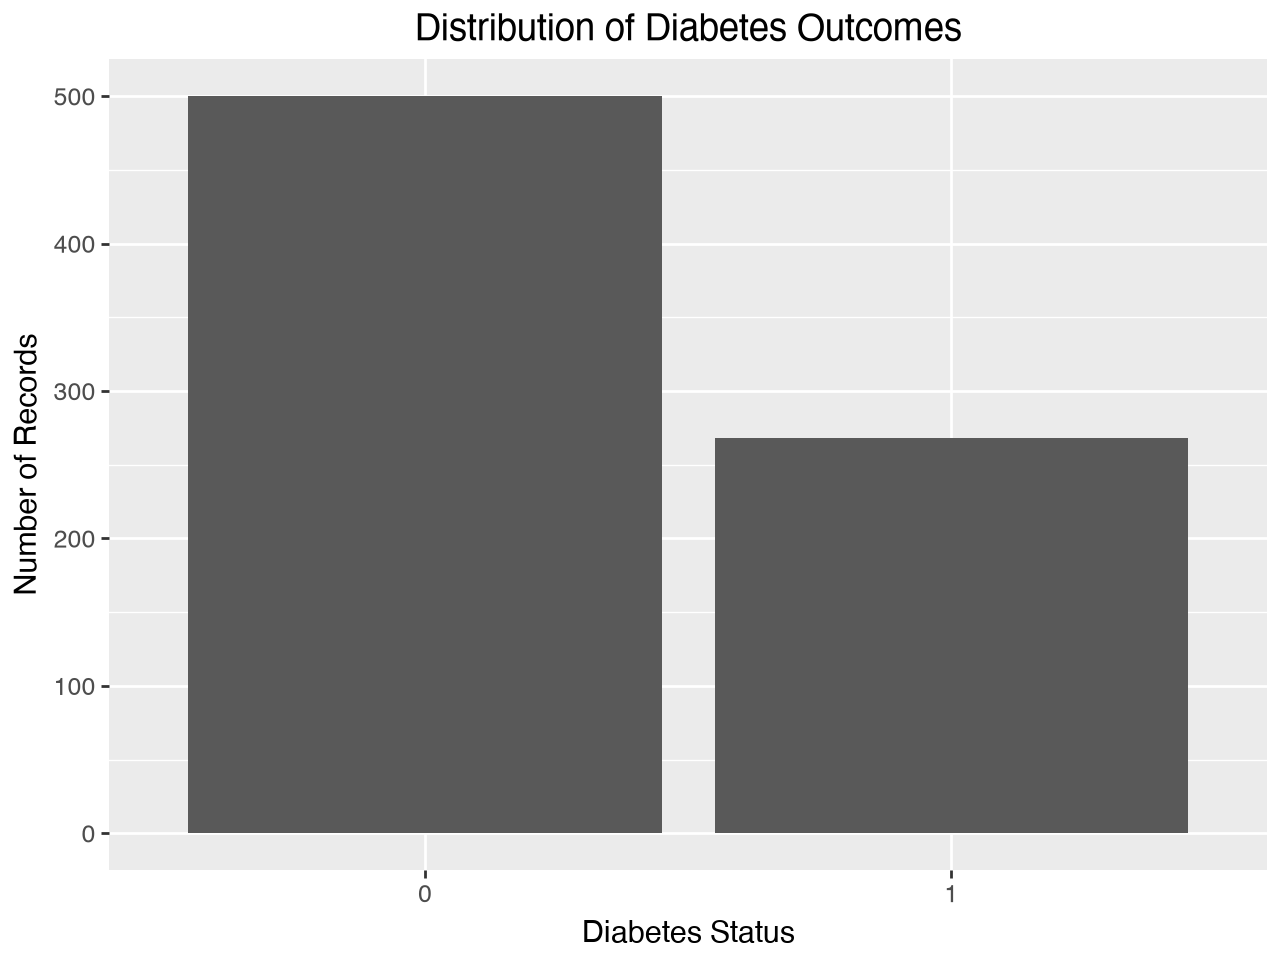

In [23]:
# Returns the distribution of the target variable "HasDiabetes"
ggplot(df, aes(x="factor(HasDiabetes)")) + \
    geom_bar() + \
    labs(
        title="Distribution of Diabetes Outcomes",
        x="Diabetes Status",
        y="Number of Records"
    )

Based on the bar graph, there are 500 observations that do not have diabetes (65.1%). There are 268 observations that have diabetes (34.9%). Because there are more observations that do not have diabetes, a **stratified** sample will be used to divide into testing and training data.